# 1. SVM, RBF Kernel and the Discrete Fourier Transform

Practice for module 1: a kernel SVM trained in its convex dual form (support vectors = α > 0),
linear vs RBF kernels, the effect of γ and C, then the DFT as a matrix multiplication,
its inverse, and the 2D DFT of an image with low-pass reconstruction.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 1.1 Kernel SVM in the dual

Dual problem: maximize `Σα - ½ ΣΣ αᵢαⱼyᵢyⱼK(xᵢ,xⱼ)` subject to `0 ≤ α ≤ C`. It is convex, so simple
coordinate ascent reaches the global optimum. The bias is absorbed by using `K + 1`.
Decision function: `f(x) = Σ αⱼ yⱼ K(xⱼ, x)`.

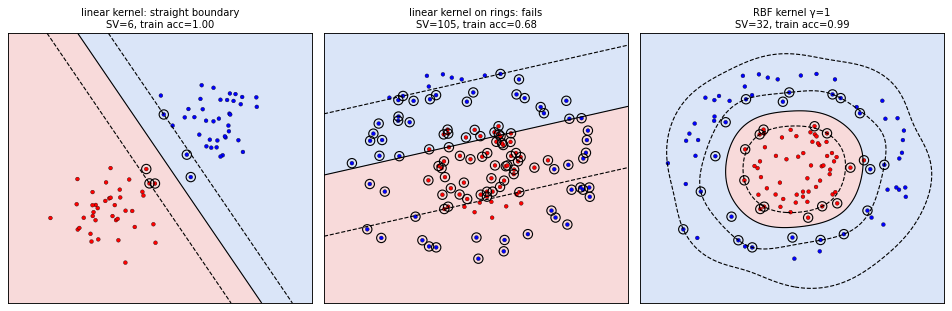

circled points = support vectors (α > 0); every other point has α = 0 and does not affect the boundary


In [2]:
def linear_kernel(A, B, gamma=None): return A @ B.T
def rbf_kernel(A, B, gamma=1.0):
    d2 = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None] - 2 * A @ B.T
    return np.exp(-gamma * d2)

class KernelSVM:
    def __init__(self, kernel=rbf_kernel, gamma=1.0, C=1.0):
        self.kernel, self.gamma, self.C = kernel, gamma, C

    def fit(self, X, y, epochs=200):
        self.X, self.y = X, y
        K = self.kernel(X, X, self.gamma) + 1                  # +1 = bias term
        a = np.zeros(len(y))
        for _ in range(epochs):                                # dual coordinate ascent
            for i in rng.permutation(len(y)):
                grad = y[i] * (K[i] @ (a * y)) - 1
                a[i] = np.clip(a[i] - grad / K[i, i], 0, self.C)
        self.alpha = a
        return self

    def decision(self, Xn):
        return (self.kernel(Xn, self.X, self.gamma) + 1) @ (self.alpha * self.y)

    @property
    def support(self): return self.alpha > 1e-6

def plot_svm(ax, m, X, y, title):
    gx, gy = np.meshgrid(np.linspace(-3, 3, 150), np.linspace(-3, 3, 150))
    f = m.decision(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, f, levels=[-1e9, 0, 1e9], colors=["#f4c2c2", "#c2d4f4"], alpha=0.6)
    ax.contour(gx, gy, f, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=1)
    ax.scatter(*X.T, c=y, cmap="bwr_r", s=12, edgecolor="k", lw=0.3)
    ax.scatter(*X[m.support].T, s=70, facecolors="none", edgecolors="k", lw=1)
    acc = (np.sign(m.decision(X)) == y).mean()
    ax.set_title(f"{title}\nSV={m.support.sum()}, train acc={acc:.2f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

# Linearly separable blobs
Xl = np.r_[rng.normal([-1, -1], 0.5, (40, 2)), rng.normal([1.2, 1], 0.5, (40, 2))]
yl = np.r_[-np.ones(40), np.ones(40)]
lin = KernelSVM(linear_kernel, C=1.0).fit(Xl, yl)

# Ring data: not linearly separable
r = np.r_[rng.normal(0.8, 0.2, 60), rng.normal(2.0, 0.25, 60)]
t = rng.uniform(0, 2 * np.pi, 120)
Xr = np.c_[r * np.cos(t), r * np.sin(t)]; yr = np.r_[-np.ones(60), np.ones(60)]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
plot_svm(axes[0], lin, Xl, yl, "linear kernel: straight boundary")
plot_svm(axes[1], KernelSVM(linear_kernel).fit(Xr, yr), Xr, yr, "linear kernel on rings: fails")
plot_svm(axes[2], KernelSVM(rbf_kernel, gamma=1.0).fit(Xr, yr), Xr, yr, "RBF kernel γ=1")
plt.tight_layout(); plt.show()
print("circled points = support vectors (α > 0); every other point has α = 0 and does not affect the boundary")

## 1.2 Only the support vectors matter

Dropping every point with α = 0 and retraining gives the same boundary.

In [3]:
m_full = KernelSVM(rbf_kernel, gamma=1.0).fit(Xr, yr)
sv = m_full.support
m_sv = KernelSVM(rbf_kernel, gamma=1.0).fit(Xr[sv], yr[sv])
grid = rng.uniform(-3, 3, (500, 2))
agree = (np.sign(m_full.decision(grid)) == np.sign(m_sv.decision(grid))).mean()
print(f"{sv.sum()} of {len(yr)} points are support vectors; predictions agree on {agree:.1%} of random test points")

32 of 120 points are support vectors; predictions agree on 100.0% of random test points


## 1.3 Effect of γ and C

Small γ = wide kernel, smooth boundary; large γ = narrow kernel, wiggly boundary around single points.
C trades margin width against training errors.

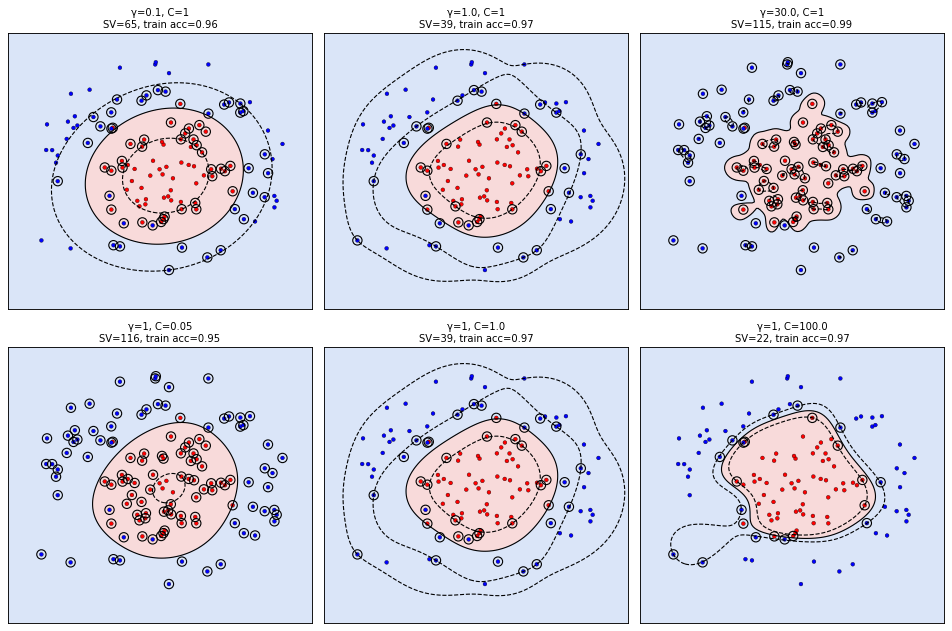

In [4]:
Xn = Xr + rng.normal(0, 0.25, Xr.shape)     # noisier rings
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, g in zip(axes[0], [0.1, 1.0, 30.0]):
    plot_svm(ax, KernelSVM(rbf_kernel, gamma=g, C=1.0).fit(Xn, yr), Xn, yr, f"γ={g}, C=1")
for ax, C in zip(axes[1], [0.05, 1.0, 100.0]):
    plot_svm(ax, KernelSVM(rbf_kernel, gamma=1.0, C=C).fit(Xn, yr), Xn, yr, f"γ=1, C={C}")
plt.tight_layout(); plt.show()

## 1.4 Bias shifts, w rotates

For a linear decision function `w·x + b`, changing `b` moves the line parallel to itself.

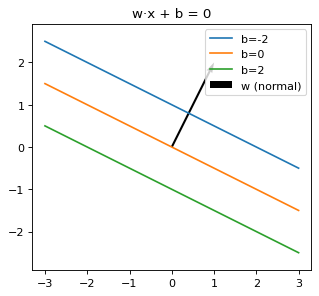

In [5]:
w = np.array([1.0, 2.0])
xs = np.linspace(-3, 3, 10)
plt.figure(figsize=(4.5, 4))
for b in [-2, 0, 2]:
    plt.plot(xs, -(w[0] * xs + b) / w[1], label=f"b={b}")
plt.quiver(0, 0, *w, angles="xy", scale_units="xy", scale=1, color="k", label="w (normal)")
plt.axis("equal"); plt.legend(); plt.title("w·x + b = 0"); plt.show()

## 1.5 The DFT as a matrix multiplication

Row k of the Fourier matrix `W[k, n] = exp(-2πi kn/N)` is a cos/sin pair with k cycles over the signal.
`X = W x` is one matmul: a fixed (not learned) linear layer.

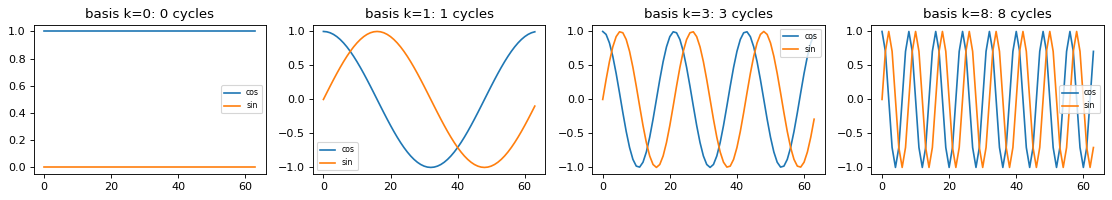

basis is orthogonal: W* Wᵀ == N·I -> True
matmul DFT == np.fft.fft: True


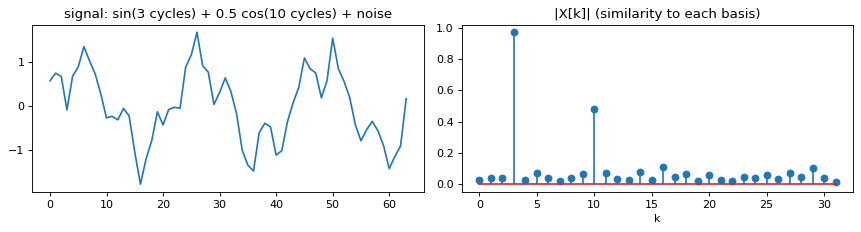

In [6]:
N = 64
n = np.arange(N)
W = np.exp(-2j * np.pi * np.outer(n, n) / N)

fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, k in zip(axes, [0, 1, 3, 8]):
    ax.plot(n, W[k].real, label="cos"); ax.plot(n, -W[k].imag, label="sin")
    ax.set_title(f"basis k={k}: {k} cycles"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

gram = W.conj() @ W.T
print("basis is orthogonal: W* Wᵀ == N·I ->", np.allclose(gram, N * np.eye(N)))

x = np.sin(2 * np.pi * 3 * n / N) + 0.5 * np.cos(2 * np.pi * 10 * n / N) + 0.2 * rng.normal(size=N)
X = W @ x
print("matmul DFT == np.fft.fft:", np.allclose(X, np.fft.fft(x)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(x); axes[0].set_title("signal: sin(3 cycles) + 0.5 cos(10 cycles) + noise")
axes[1].stem(n[:N // 2], np.abs(X[:N // 2]) / N * 2); axes[1].set_title("|X[k]| (similarity to each basis)")
axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

## 1.6 Inverse DFT

Same basis, opposite sign in the exponent, scaled by `1/N`: `x = (1/N) W* X`.

IDFT recovers x: True  max imag part: 1.6653345369377348e-14


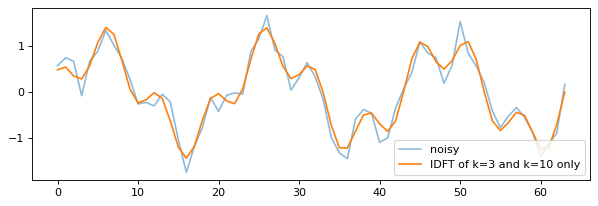

In [7]:
W_inv = W.conj() / N
x_rec = W_inv @ X
print("IDFT recovers x:", np.allclose(x_rec.real, x), " max imag part:", np.abs(x_rec.imag).max())

# keep only the two strongest frequencies (and their mirrors) -> denoised signal
keep = np.zeros(N, bool)
keep[[3, N - 3, 10, N - 10]] = True
x_clean = (W_inv @ (X * keep)).real
plt.figure(figsize=(9, 2.8))
plt.plot(x, alpha=0.5, label="noisy"); plt.plot(x_clean, label="IDFT of k=3 and k=10 only")
plt.legend(); plt.show()

## 1.7 2D DFT of an image

The 2D basis `exp(-2πi(ux/M + vy/N))` is separable, so the 2D DFT is `W_M · img · W_N`.
The 2D IDFT scales by `1/(M·N)`. Keeping only low frequencies keeps the overall shape and blurs edges.

matmul 2D DFT == np.fft.fft2: True
2D IDFT with 1/(M·N) recovers the image: True


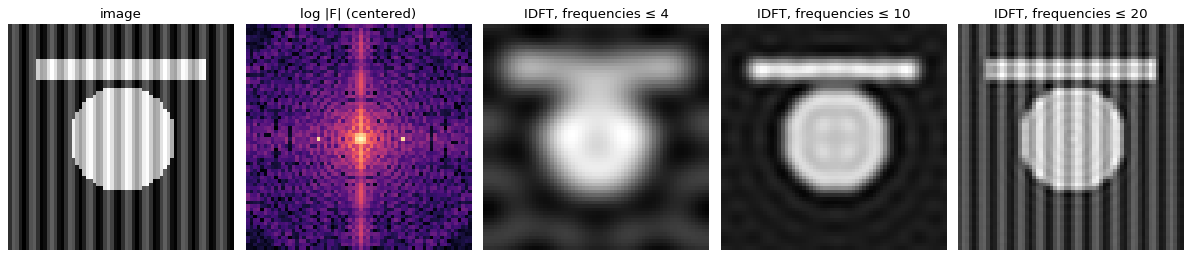

In [8]:
M = Nn = 64
yy, xx = np.mgrid[:M, :Nn]
img = ((xx - 32) ** 2 + (yy - 32) ** 2 < 15 ** 2).astype(float)
img[10:16, 8:56] = 1.0
img += 0.3 * np.sin(2 * np.pi * 12 * xx / Nn)          # fine stripes = one high frequency

WM = np.exp(-2j * np.pi * np.outer(np.arange(M), np.arange(M)) / M)
WN = np.exp(-2j * np.pi * np.outer(np.arange(Nn), np.arange(Nn)) / Nn)
F = WM @ img @ WN
print("matmul 2D DFT == np.fft.fft2:", np.allclose(F, np.fft.fft2(img)))
rec = (WM.conj() @ F @ WN.conj()) / (M * Nn)
print("2D IDFT with 1/(M·N) recovers the image:", np.allclose(rec.real, img))

u = np.fft.fftfreq(M) * M
U, V = np.meshgrid(u, u, indexing="ij")
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("image")
axes[1].imshow(np.log1p(np.abs(np.fft.fftshift(F))), cmap="magma"); axes[1].set_title("log |F| (centered)")
for ax, R in zip(axes[2:], [4, 10, 20]):
    low = (np.sqrt(U ** 2 + V ** 2) <= R)
    ax.imshow(((WM.conj() @ (F * low) @ WN.conj()) / (M * Nn)).real, cmap="gray")
    ax.set_title(f"IDFT, frequencies ≤ {R}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 1.8 Individual 2D basis functions

Each (u, v) pair is a plane wave: u cycles vertically, v cycles horizontally.

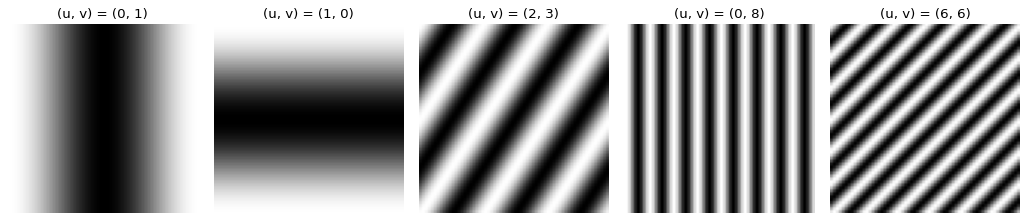

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(13, 2.7))
for ax, (uu, vv) in zip(axes, [(0, 1), (1, 0), (2, 3), (0, 8), (6, 6)]):
    ax.imshow(np.cos(2 * np.pi * (uu * yy / M + vv * xx / Nn)), cmap="gray")
    ax.set_title(f"(u, v) = ({uu}, {vv})"); ax.axis("off")
plt.tight_layout(); plt.show()